# Victorian Electricity Demand — Exploratory Analysis

This notebook explores temporal patterns and peak-demand behaviour in Victorian electricity demand before developing forecasting models.

## 1. Setup and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

demand = pd.read_parquet(
    PROCESSED_DATA_DIR / "vic_demand_2025_30min.parquet"
)

print(demand.shape)
display(demand.head())

(17520, 2)


,datetime,demand_mw
0,2025-01-01 00:00:00,4281.094000
1,2025-01-01 00:30:00,4180.268333
2,2025-01-01 01:00:00,4093.626667
3,2025-01-01 01:30:00,3985.283333
4,2025-01-01 02:00:00,3876.845000


## 2. Time Features

Create calendar and time variables to investigate how electricity demand changes across hours, days and seasons.

In [3]:
demand["hour"] = demand["datetime"].dt.hour + demand["datetime"].dt.minute / 60

demand["day_of_week"] = demand["datetime"].dt.day_name()

demand["month"] = demand["datetime"].dt.month

demand["month_name"] = demand["datetime"].dt.month_name()

demand["is_weekend"] = demand["datetime"].dt.dayofweek >= 5

display(demand.head())

,datetime,demand_mw,hour,day_of_week,month,month_name,is_weekend
0,2025-01-01 00:00:00,4281.094000,0.0,Wednesday,1,January,False
1,2025-01-01 00:30:00,4180.268333,0.5,Wednesday,1,January,False
2,2025-01-01 01:00:00,4093.626667,1.0,Wednesday,1,January,False
3,2025-01-01 01:30:00,3985.283333,1.5,Wednesday,1,January,False
4,2025-01-01 02:00:00,3876.845000,2.0,Wednesday,1,January,False


## 3. Intraday Demand Patterns

Investigate how average electricity demand changes throughout the day.

In [4]:
hourly_demand = (
    demand.groupby("hour", as_index=False)["demand_mw"]
    .mean()
)

display(hourly_demand)

,hour,demand_mw
0,0.0,4832.840468
1,0.5,4679.500776
2,1.0,4553.828178
3,1.5,4419.964059
4,2.0,4316.942580
5,2.5,4244.417795
6,3.0,4213.604872
7,3.5,4215.418174
8,4.0,4264.874151
9,4.5,4353.112196


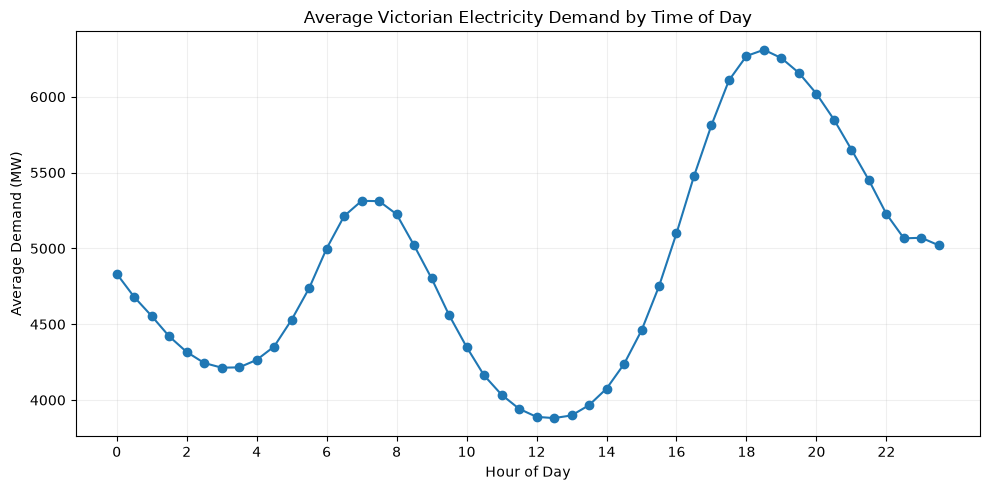

In [5]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand["hour"],
    hourly_demand["demand_mw"],
    marker="o"
)

plt.title("Average Victorian Electricity Demand by Time of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

**Finding:** Demand follows a clear intraday pattern, with a smaller morning peak around 7–8am and a much larger evening peak around 6–7pm. Average demand falls to its lowest level around midday before rising sharply through the afternoon.

**Implication:** Time of day is likely to be an important predictor of short-term electricity demand.

## 4. Weekly Demand Patterns

Compare average demand across weekdays and weekends to identify recurring weekly behaviour.

In [6]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_demand = (
    demand.groupby("day_of_week")["demand_mw"]
    .mean()
    .reindex(day_order)
)

display(daily_demand)

day_of_week
Monday       4960.254963
Tuesday      5038.611613
Wednesday    5019.121744
Thursday     5057.407601
Friday       5025.372513
Saturday     4573.009100
Sunday       4491.742124
Name: demand_mw, dtype: float64

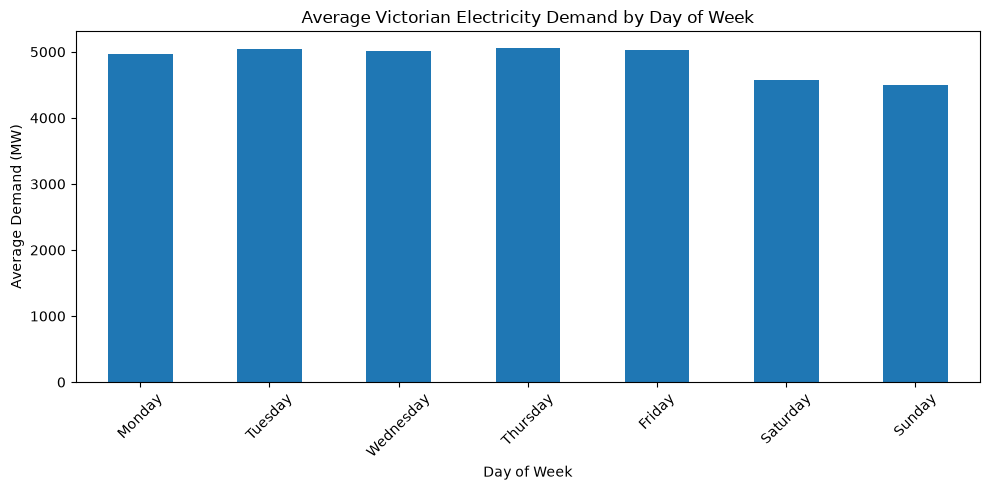

In [7]:
plt.figure(figsize=(10, 5))

daily_demand.plot(kind="bar")

plt.title("Average Victorian Electricity Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Demand (MW)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [8]:
weekend_comparison = (
    demand.groupby("is_weekend")["demand_mw"]
    .agg(["mean", "median", "max"])
)

weekend_comparison.index = ["Weekday", "Weekend"]

display(weekend_comparison)

,mean,median,max
Weekday,5020.149733,4892.121667,9421.428333
Weekend,4532.375612,4474.365000,9307.028333


**Finding:** Average weekday demand is approximately 5,020 MW compared with 4,532 MW on weekends, around 11% higher.

**Implication:** Recurring calendar patterns contain useful information for explaining and forecasting demand.

## 5. Seasonal Demand Patterns

Examine how average and peak electricity demand vary throughout the year.

In [9]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_demand = (
    demand.groupby("month_name")["demand_mw"]
    .agg(["mean", "max"])
    .reindex(month_order)
)

display(monthly_demand.round(1))

,mean,max
month_name,,
January,4408.2,8666.6
February,4829.7,9421.4
March,4683.5,8427.6
April,4456.7,6367.8
May,5035.5,7961.1
June,5869.3,8484.9
July,5942.0,8350.2
August,5550.8,8152.9
September,4821.9,7482.9


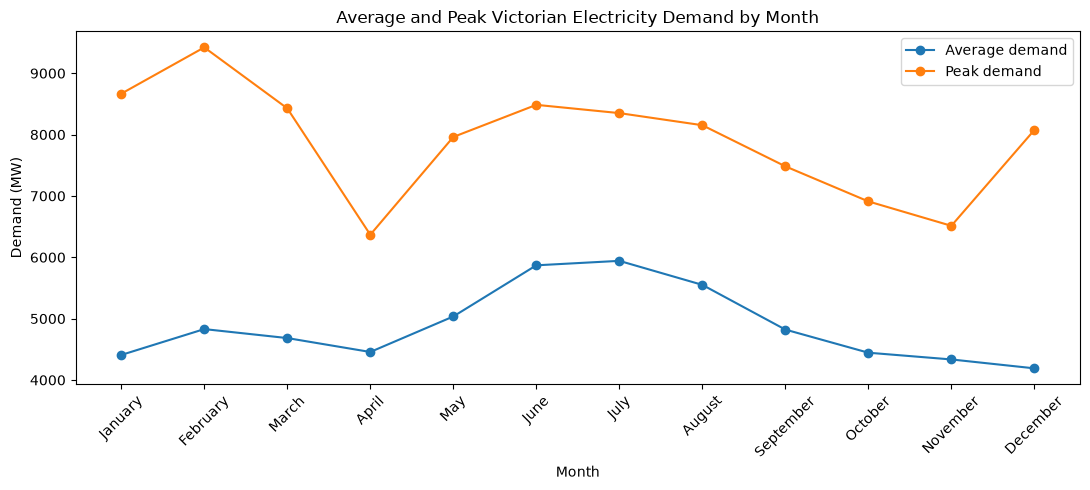

In [10]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_demand.index,
    monthly_demand["mean"],
    marker="o",
    label="Average demand"
)

plt.plot(
    monthly_demand.index,
    monthly_demand["max"],
    marker="o",
    label="Peak demand"
)

plt.title("Average and Peak Victorian Electricity Demand by Month")
plt.xlabel("Month")
plt.ylabel("Demand (MW)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

**Finding:** Winter produces the highest sustained demand, with June and July averaging approximately 5,870–5,940 MW. However, the highest single demand observation occurs in February at approximately 9,421 MW.

**Implication:** The factors driving typical demand may differ from those driving extreme demand events. Weather is a plausible driver worth investigating.

## 6. Peak Demand Events

Identify the highest-demand periods of 2025 and examine when extreme demand occurs.

In [11]:
top_demand = (
    demand.nlargest(20, "demand_mw")
    [["datetime", "demand_mw", "day_of_week"]]
)

display(top_demand)

,datetime,demand_mw,day_of_week
1621,2025-02-03 18:30:00,9421.428333,Monday
1571,2025-02-02 17:30:00,9307.028333,Sunday
1572,2025-02-02 18:00:00,9228.246667,Sunday
1620,2025-02-03 18:00:00,9148.440000,Monday
1573,2025-02-02 18:30:00,9141.498333,Sunday
1619,2025-02-03 17:30:00,9095.151667,Monday
1570,2025-02-02 17:00:00,9050.710000,Sunday
1622,2025-02-03 19:00:00,9043.116667,Monday
2052,2025-02-12 18:00:00,9036.623333,Wednesday
1618,2025-02-03 17:00:00,9005.795000,Monday


In [12]:
peak_threshold = demand["demand_mw"].quantile(0.99)

print(f"99th percentile demand threshold: {peak_threshold:.1f} MW")

demand["is_peak"] = demand["demand_mw"] >= peak_threshold

print(f"Number of peak observations: {demand['is_peak'].sum()}")

99th percentile demand threshold: 7825.5 MW
Number of peak observations: 176


In [13]:
peak_by_month = (
    demand[demand["is_peak"]]
    .groupby("month_name")
    .size()
    .reindex(month_order, fill_value=0)
)

display(peak_by_month)

month_name
January       6
February     50
March        14
April         0
May           2
June         48
July         41
August       12
September     0
October       0
November      0
December      3
dtype: int64

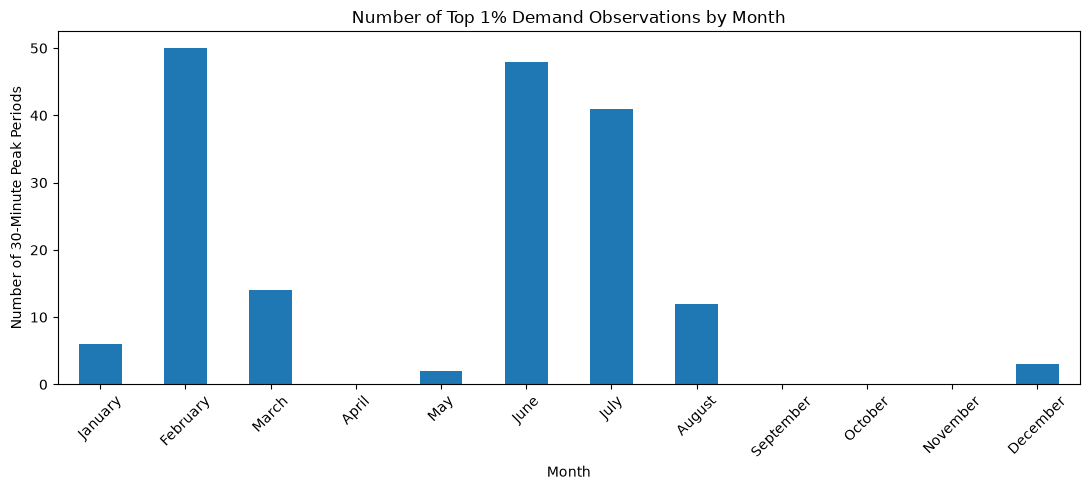

In [14]:
plt.figure(figsize=(11, 5))

peak_by_month.plot(kind="bar")

plt.title("Number of Top 1% Demand Observations by Month")
plt.xlabel("Month")
plt.ylabel("Number of 30-Minute Peak Periods")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Finding:** Extreme demand is concentrated in both summer and winter. February records the most top-1% demand periods, while June and July also contain substantial numbers of extreme observations.

**Next question:** Can temperature help explain why extreme demand occurs in both seasons?